# Task 4: Loan Approval Prediction

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
import joblib

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("loan_approval_dataset.csv")
df.columns = df.columns.str.strip()
print("Shape:", df.shape)
df.head()

Shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


## Cleaning target and predictor variables

In [4]:
TARGET = "loan_status"
df = df.dropna(subset=[TARGET]).copy()
y_raw = df[TARGET].astype(str).str.strip()

In [5]:
encoder = LabelEncoder()
y = pd.Series(encoder.fit_transform(y_raw), index=y_raw.index)
class_names = list(encoder.classes_)

In [6]:
X = df.drop(columns=[TARGET])
X = X.drop(columns=[c for c in ["Loan_ID", "CustomerID", "customer_id"] if c in X.columns])
print("Target distribution:"); display(y.value_counts())
print("Predictor shape:", X.shape)

Target distribution:


0    2656
1    1613
Name: count, dtype: int64

Predictor shape: (4269, 12)


## Split into training and testing sets

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training:", X_train.shape, "Testing:", X_test.shape)

Training: (3415, 12) Testing: (854, 12)


## Preprocess numerical and categorical columns
Missing numeric values are replaced with medians; categorical values with their most frequent category. Categorical columns are one-hot encoded.

In [8]:
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

In [9]:
onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

category_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", onehot)])

preprocessor = ColumnTransformer([("numeric", numeric_pipe, numeric_cols), ("categorical", category_pipe, categorical_cols)])

print("Numerical:", numeric_cols)
print("Categorical:", categorical_cols)

Numerical: ['loan_id', 'no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Categorical: ['education', 'self_employed']


## Training and comparision classification models

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
}

In [11]:
trained_models = {}
rows = []
for name, estimator in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    trained_models[name] = pipeline
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="binary", zero_division=0),
        "Recall": recall_score(y_test, pred, average="binary", zero_division=0),
        "F1-score": f1_score(y_test, pred, average="binary", zero_division=0)
    })
    print("\n", name, "\n", classification_report(y_test, pred, zero_division=0))


 Logistic Regression 
               precision    recall  f1-score   support

           0       0.96      0.94      0.95       531
           1       0.91      0.93      0.92       323

    accuracy                           0.94       854
   macro avg       0.93      0.94      0.93       854
weighted avg       0.94      0.94      0.94       854


 Decision Tree 
               precision    recall  f1-score   support

           0       0.99      0.97      0.98       531
           1       0.95      0.99      0.97       323

    accuracy                           0.98       854
   macro avg       0.97      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



## Evaluatio of models performance with confusion matrices

In [12]:
comparison = pd.DataFrame(rows).sort_values("F1-score", ascending=False)
display(comparison)

,Model,Accuracy,Precision,Recall,F1-score
1,Decision Tree,0.977752,0.952381,0.990712,0.971168
0,Logistic Regression,0.936768,0.906344,0.928793,0.917431


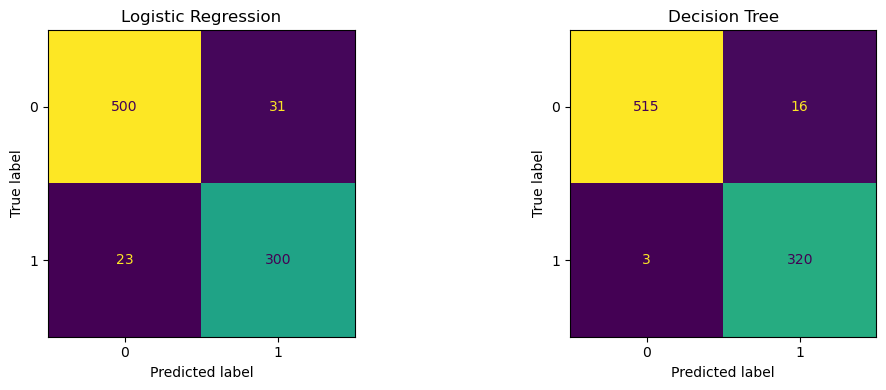

In [13]:
fig, axes = plt.subplots(1, len(trained_models), figsize=(11,4))
for ax, (name, pipeline) in zip(np.atleast_1d(axes), trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(pipeline, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## Best Model

In [14]:
best_name = comparison.iloc[0]["Model"]
best_model = trained_models[best_name]

In [15]:
joblib.dump(best_model, "best_loan_approval_model.joblib")
comparison.to_csv("loan_model_comparison.csv", index=False)
print("Best model by F1-score:", best_name)
print("Saved best_loan_approval_model.joblib and loan_model_comparison.csv")

Best model by F1-score: Decision Tree
Saved best_loan_approval_model.joblib and loan_model_comparison.csv


## Conclusion
Decision Tree is the best model as it has the highest Accuracy, F1-score, Recall and Precision compared to Logistic Regression. 